In [ ]:
import numpy as np
import tensorflow as tf
import pandas as pd
import time
from sklearn.metrics import mean_squared_error, r2_score

okul_no = 17

p_giris = np.linspace(-2, 2, 400).reshape(-1, 1)
t_hedef = 1 + np.sin(np.pi * p_giris / 4)

aktivasyon_fonksiyonlari = [
    'linear',
    'sigmoid',
    'tanh',
    'relu',
    tf.keras.layers.LeakyReLU(),
    'elu',
    'swish'
]
aktivasyon_isimleri = ['Lineer', 'Sigmoid', 'Hiperbolik Tanjant', 'ReLU', 'LeakyReLU', 'ELU', 'SİLU']

sonuclar = []

print("Tablo 1 hesaplanıyor, lütfen bekleyin...\n")

for i in range(len(aktivasyon_fonksiyonlari)):
    np.random.seed(okul_no)
    tf.random.set_seed(okul_no)

    model = tf.keras.Sequential()
    baslangic = tf.keras.initializers.RandomNormal(seed=okul_no)

    model.add(tf.keras.layers.Dense(2, activation=aktivasyon_fonksiyonlari[i], kernel_initializer=baslangic, input_shape=(1,)))
    model.add(tf.keras.layers.Dense(1, activation='linear', kernel_initializer=baslangic))

    opt = tf.keras.optimizers.SGD(learning_rate=0.1)
    model.compile(optimizer=opt, loss='mse')

    basla = time.time()
    model.fit(p_giris, t_hedef, epochs=300, verbose=0)
    bitis = time.time()

    sure = bitis - basla
    tahmin = model.predict(p_giris, verbose=0)

    mse = mean_squared_error(t_hedef, tahmin)
    r2 = r2_score(t_hedef, tahmin)

    sonuclar.append([aktivasyon_isimleri[i], round(mse, 5), round(r2, 5), round(sure, 2)])

df = pd.DataFrame(sonuclar, columns=["Aktivasyon", "MSE", "R2", "Süre (sn)"])
print(df.to_string(index=False))

Tablo 1 hesaplanıyor, lütfen bekleyin...



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr

        Aktivasyon     MSE      R2  Süre (sn)
            Lineer 0.00740 0.98524      25.22
           Sigmoid 0.00010 0.99980      23.33
Hiperbolik Tanjant 0.00010 0.99981      21.21
              ReLU 0.00531 0.98940      22.17
         LeakyReLU 0.00522 0.98959      22.62
               ELU 0.00562 0.98878      21.32
              SİLU 0.00735 0.98534      22.09


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


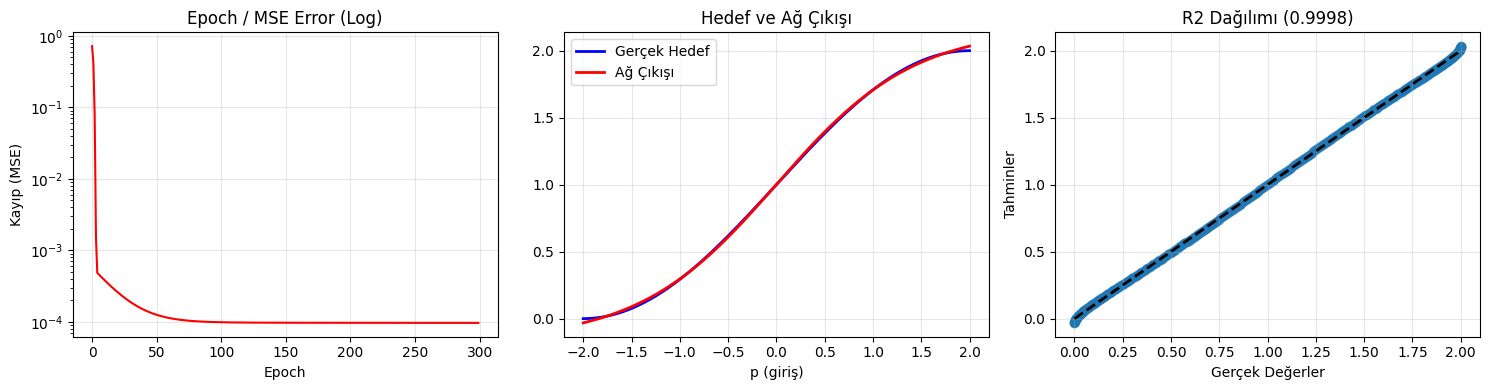

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# Okul no ve veri seti
okul_no = 17
np.random.seed(okul_no)
tf.random.set_seed(okul_no)

p_giris = np.linspace(-2, 2, 400).reshape(-1, 1)
t_hedef = 1 + np.sin(np.pi * p_giris / 4)

# Sadece En İyi Model (Hiperbolik Tanjant) Kuruluyor
model = tf.keras.Sequential()
baslangic = tf.keras.initializers.RandomNormal(seed=okul_no)
model.add(tf.keras.layers.Dense(2, activation='tanh', kernel_initializer=baslangic, input_shape=(1,)))
model.add(tf.keras.layers.Dense(1, activation='linear', kernel_initializer=baslangic))

opt = tf.keras.optimizers.SGD(learning_rate=0.1)
model.compile(optimizer=opt, loss='mse')

# Eğitim
history = model.fit(p_giris, t_hedef, epochs=300, verbose=0)
tahmin = model.predict(p_giris, verbose=0)
r2 = r2_score(t_hedef, tahmin)

# 3 Grafiği Çizdirme
plt.figure(figsize=(15, 4))

# 1. Grafik: MSE Loss (Logaritmik)
plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], color='red')
plt.yscale('log')
plt.title('Epoch / MSE Error (Log)')
plt.xlabel('Epoch')
plt.ylabel('Kayıp (MSE)')
plt.grid(True, alpha=0.3)

# 2. Grafik: Hedef ve Çıkış
plt.subplot(1, 3, 2)
plt.plot(p_giris, t_hedef, label='Gerçek Hedef', color='blue', linewidth=2)
plt.plot(p_giris, tahmin, label='Ağ Çıkışı', color='red', linewidth=2)
plt.title('Hedef ve Ağ Çıkışı')
plt.xlabel('p (giriş)')
plt.legend()
plt.grid(True, alpha=0.3)

# 3. Grafik: R2
plt.subplot(1, 3, 3)
plt.scatter(t_hedef, tahmin, alpha=0.5)
plt.plot([t_hedef.min(), t_hedef.max()], [t_hedef.min(), t_hedef.max()], 'k--', lw=2)
plt.title(f'R2 Dağılımı ({r2:.4f})')
plt.xlabel('Gerçek Değerler')
plt.ylabel('Tahminler')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


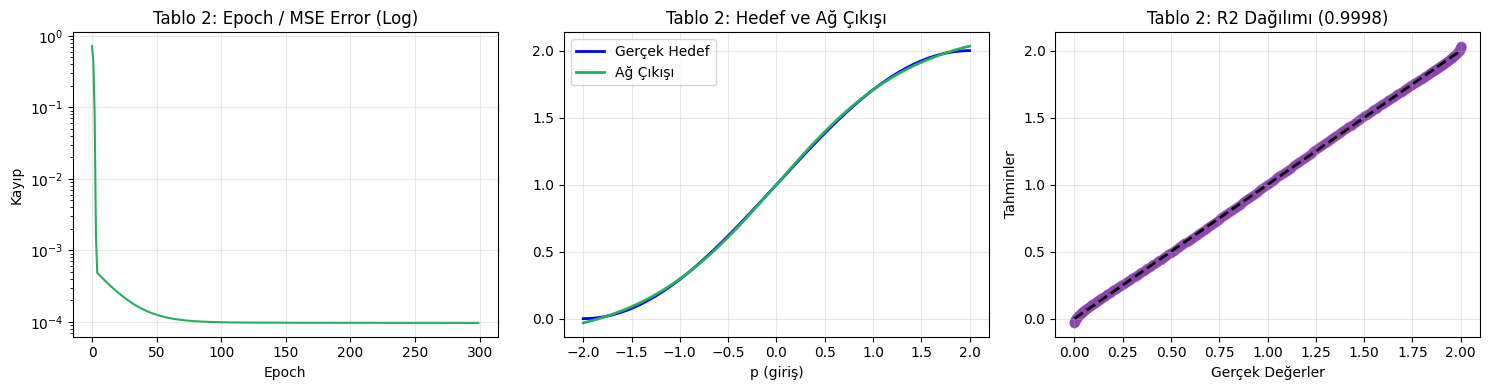

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

okul_no = 17
np.random.seed(okul_no)
tf.random.set_seed(okul_no)

p_giris = np.linspace(-2, 2, 400).reshape(-1, 1)
t_hedef = 1 + np.sin(np.pi * p_giris / 4)

model = tf.keras.Sequential()
baslangic = tf.keras.initializers.RandomNormal(seed=okul_no)
model.add(tf.keras.layers.Dense(2, activation='tanh', kernel_initializer=baslangic, input_shape=(1,)))
model.add(tf.keras.layers.Dense(1, activation='linear', kernel_initializer=baslangic))

# En iyi oran: 0.1
opt = tf.keras.optimizers.SGD(learning_rate=0.1)
model.compile(optimizer=opt, loss='mse')

history = model.fit(p_giris, t_hedef, epochs=300, verbose=0)
tahmin = model.predict(p_giris, verbose=0)
r2 = r2_score(t_hedef, tahmin)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], color='#27ae60')
plt.yscale('log')
plt.title('Tablo 2: Epoch / MSE Error (Log)')
plt.xlabel('Epoch')
plt.ylabel('Kayıp')
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(p_giris, t_hedef, label='Gerçek Hedef', color='blue', linewidth=2)
plt.plot(p_giris, tahmin, label='Ağ Çıkışı', color='#27ae60', linewidth=2)
plt.title('Tablo 2: Hedef ve Ağ Çıkışı')
plt.xlabel('p (giriş)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)
plt.scatter(t_hedef, tahmin, alpha=0.5, color='#8e44ad')
plt.plot([t_hedef.min(), t_hedef.max()], [t_hedef.min(), t_hedef.max()], 'k--', lw=2)
plt.title(f'Tablo 2: R2 Dağılımı ({r2:.4f})')
plt.xlabel('Gerçek Değerler')
plt.ylabel('Tahminler')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import tensorflow as tf
import pandas as pd
import time
from sklearn.metrics import mean_squared_error, r2_score

# Okul no ve veri seti
okul_no = 17
p_giris = np.linspace(-2, 2, 400).reshape(-1, 1)
t_hedef = 1 + np.sin(np.pi * p_giris / 4)

# Tablo 3 için Optimizasyon Yöntemleri
optimizatorler = ['SGD', 'RMSprop', 'Adam']
sonuclar_t3 = []

print("Tablo 3 (Ayar Yöntemi) hesaplanıyor...\n")

for opt_isim in optimizatorler:
    np.random.seed(okul_no)
    tf.random.set_seed(okul_no)

    model = tf.keras.Sequential()
    baslangic = tf.keras.initializers.RandomNormal(seed=okul_no)

    # En iyi aktivasyon: tanh
    model.add(tf.keras.layers.Dense(2, activation='tanh', kernel_initializer=baslangic, input_shape=(1,)))
    model.add(tf.keras.layers.Dense(1, activation='linear', kernel_initializer=baslangic))

    # En iyi öğrenme oranı (0.1) ile optimizatörü seçiyoruz
    if opt_isim == 'SGD':
        opt = tf.keras.optimizers.SGD(learning_rate=0.1)
    elif opt_isim == 'RMSprop':
        opt = tf.keras.optimizers.RMSprop(learning_rate=0.1)
    else:
        opt = tf.keras.optimizers.Adam(learning_rate=0.1)

    model.compile(optimizer=opt, loss='mse')

    basla = time.time()
    model.fit(p_giris, t_hedef, epochs=300, verbose=0)
    bitis = time.time()

    sure = bitis - basla
    tahmin = model.predict(p_giris, verbose=0)

    mse = mean_squared_error(t_hedef, tahmin)
    r2 = r2_score(t_hedef, tahmin)

    sonuclar_t3.append([opt_isim, round(mse, 5), round(r2, 5), round(sure, 2)])

df_t3 = pd.DataFrame(sonuclar_t3, columns=["Ayar Yöntemi", "MSE", "R2", "Süre (sn)"])
print(df_t3.to_string(index=False))

Tablo 3 (Ayar Yöntemi) hesaplanıyor...



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Ayar Yöntemi     MSE      R2  Süre (sn)
         SGD 0.00010 0.99981      23.43
     RMSprop 0.00418 0.99166      22.94
        Adam 0.00017 0.99967      24.27


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


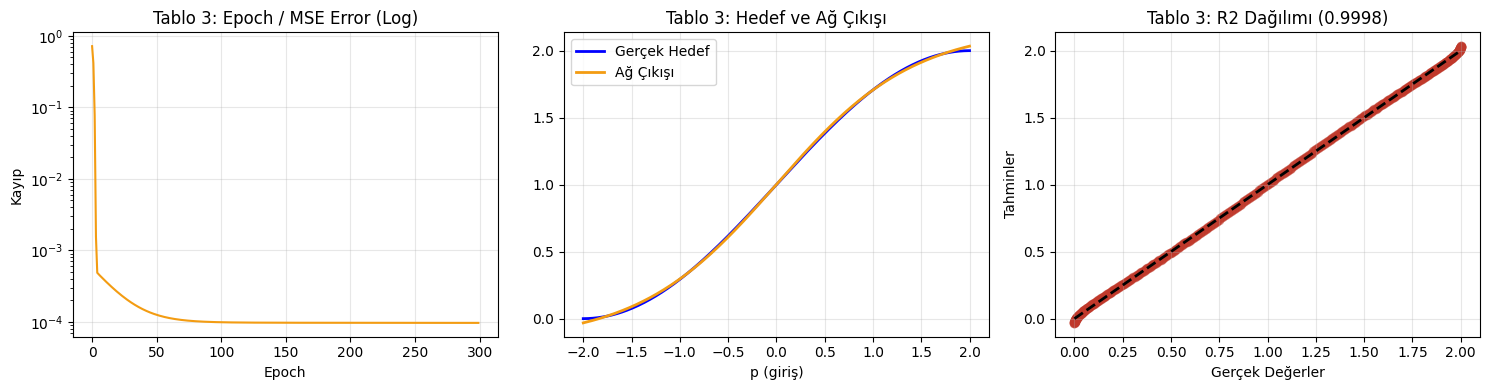

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

okul_no = 17
np.random.seed(okul_no)
tf.random.set_seed(okul_no)

p_giris = np.linspace(-2, 2, 400).reshape(-1, 1)
t_hedef = 1 + np.sin(np.pi * p_giris / 4)

model = tf.keras.Sequential()
baslangic = tf.keras.initializers.RandomNormal(seed=okul_no)
model.add(tf.keras.layers.Dense(2, activation='tanh', kernel_initializer=baslangic, input_shape=(1,)))
model.add(tf.keras.layers.Dense(1, activation='linear', kernel_initializer=baslangic))

# En iyi Ayar Yöntemi: SGD
opt = tf.keras.optimizers.SGD(learning_rate=0.1)
model.compile(optimizer=opt, loss='mse')

history = model.fit(p_giris, t_hedef, epochs=300, verbose=0)
tahmin = model.predict(p_giris, verbose=0)
r2 = r2_score(t_hedef, tahmin)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], color='#f39c12')
plt.yscale('log')
plt.title('Tablo 3: Epoch / MSE Error (Log)')
plt.xlabel('Epoch')
plt.ylabel('Kayıp')
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(p_giris, t_hedef, label='Gerçek Hedef', color='blue', linewidth=2)
plt.plot(p_giris, tahmin, label='Ağ Çıkışı', color='#f39c12', linewidth=2)
plt.title('Tablo 3: Hedef ve Ağ Çıkışı')
plt.xlabel('p (giriş)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)
plt.scatter(t_hedef, tahmin, alpha=0.5, color='#c0392b')
plt.plot([t_hedef.min(), t_hedef.max()], [t_hedef.min(), t_hedef.max()], 'k--', lw=2)
plt.title(f'Tablo 3: R2 Dağılımı ({r2:.4f})')
plt.xlabel('Gerçek Değerler')
plt.ylabel('Tahminler')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import tensorflow as tf
import pandas as pd
import time
from sklearn.metrics import mean_squared_error, r2_score

okul_no = 17
p_giris = np.linspace(-2, 2, 400).reshape(-1, 1)
t_hedef = 1 + np.sin(np.pi * p_giris / 4)

# Tablo 4 için Başlangıç Dağılımları
dagilimlar = ['normal', 'uniform']
sonuclar_t4 = []

print("Tablo 4 (Başlangıç Dağılımı) hesaplanıyor...\n")

for dagilim in dagilimlar:
    np.random.seed(okul_no)
    tf.random.set_seed(okul_no)

    model = tf.keras.Sequential()

    if dagilim == 'normal':
        baslangic = tf.keras.initializers.RandomNormal(seed=okul_no)
    else:
        baslangic = tf.keras.initializers.RandomUniform(seed=okul_no)

    model.add(tf.keras.layers.Dense(2, activation='tanh', kernel_initializer=baslangic, input_shape=(1,)))
    model.add(tf.keras.layers.Dense(1, activation='linear', kernel_initializer=baslangic))

    opt = tf.keras.optimizers.SGD(learning_rate=0.1)
    model.compile(optimizer=opt, loss='mse')

    basla = time.time()
    model.fit(p_giris, t_hedef, epochs=300, verbose=0)
    bitis = time.time()

    sure = bitis - basla
    tahmin = model.predict(p_giris, verbose=0)

    mse = mean_squared_error(t_hedef, tahmin)
    r2 = r2_score(t_hedef, tahmin)

    sonuclar_t4.append([dagilim, round(mse, 5), round(r2, 5), round(sure, 2)])

df_t4 = pd.DataFrame(sonuclar_t4, columns=["Dağılım", "MSE", "R2", "Süre (sn)"])
print(df_t4.to_string(index=False))

Tablo 4 (Başlangıç Dağılımı) hesaplanıyor...



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Dağılım    MSE      R2  Süre (sn)
 normal 0.0001 0.99981      24.05
uniform 0.0001 0.99980      22.95


In [ ]:
import numpy as np
import tensorflow as tf
import pandas as pd
import time
from sklearn.metrics import mean_squared_error, r2_score

okul_no = 17
p_giris = np.linspace(-2, 2, 400).reshape(-1, 1)
t_hedef = 1 + np.sin(np.pi * p_giris / 4)

# Tablo 5 için Gizli Katman Sayıları
katman_sayilari = [1, 2, 5, 10, 20]
sonuclar_t5 = []

print("Tablo 5 (Gizli Katman Sayısı) hesaplanıyor...\n")

for katman in katman_sayilari:
    np.random.seed(okul_no)
    tf.random.set_seed(okul_no)

    model = tf.keras.Sequential()
    baslangic = tf.keras.initializers.RandomNormal(seed=okul_no)

    # Giriş katmanı
    model.add(tf.keras.layers.Dense(2, activation='tanh', kernel_initializer=baslangic, input_shape=(1,)))

    # Ara gizli katmanlar (Eğer katman sayısı > 1 ise araya katman ekliyoruz)
    for _ in range(katman - 1):
        model.add(tf.keras.layers.Dense(2, activation='tanh', kernel_initializer=baslangic))

    # Çıkış katmanı
    model.add(tf.keras.layers.Dense(1, activation='linear', kernel_initializer=baslangic))

    opt = tf.keras.optimizers.SGD(learning_rate=0.1)
    model.compile(optimizer=opt, loss='mse')

    basla = time.time()
    model.fit(p_giris, t_hedef, epochs=300, verbose=0)
    bitis = time.time()

    sure = bitis - basla
    tahmin = model.predict(p_giris, verbose=0)

    mse = mean_squared_error(t_hedef, tahmin)
    r2 = r2_score(t_hedef, tahmin)

    sonuclar_t5.append([katman, round(mse, 5), round(r2, 5), round(sure, 2)])

df_t5 = pd.DataFrame(sonuclar_t5, columns=["Gizli Katman Sayısı", "MSE", "R2", "Süre (sn)"])
print(df_t5.to_string(index=False))

Tablo 5 (Gizli Katman Sayısı) hesaplanıyor...



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr

 Gizli Katman Sayısı     MSE       R2  Süre (sn)
                   1 0.00010  0.99981      23.59
                   2 0.00013  0.99974      24.46
                   5 0.50125 -0.00000      24.56
                  10 0.50125 -0.00000      24.74
                  20 0.50125 -0.00000      26.76


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


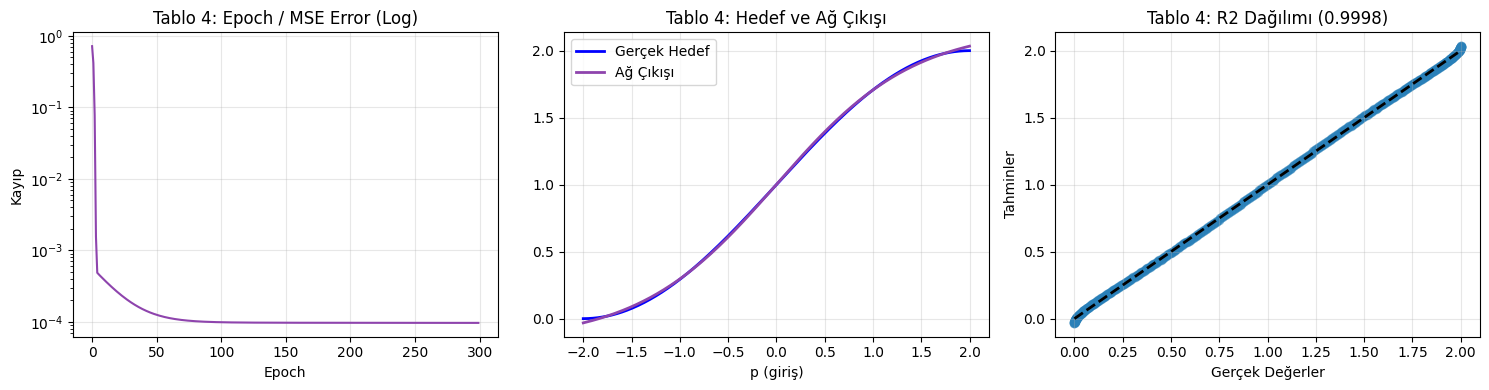

In [10]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

okul_no = 17
np.random.seed(okul_no)
tf.random.set_seed(okul_no)

p_giris = np.linspace(-2, 2, 400).reshape(-1, 1)
t_hedef = 1 + np.sin(np.pi * p_giris / 4)

model = tf.keras.Sequential()
# En iyi dağılım: normal
baslangic = tf.keras.initializers.RandomNormal(seed=okul_no)

model.add(tf.keras.layers.Dense(2, activation='tanh', kernel_initializer=baslangic, input_shape=(1,)))
model.add(tf.keras.layers.Dense(1, activation='linear', kernel_initializer=baslangic))

opt = tf.keras.optimizers.SGD(learning_rate=0.1)
model.compile(optimizer=opt, loss='mse')

history = model.fit(p_giris, t_hedef, epochs=300, verbose=0)
tahmin = model.predict(p_giris, verbose=0)
r2 = r2_score(t_hedef, tahmin)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], color='#8e44ad')
plt.yscale('log')
plt.title('Tablo 4: Epoch / MSE Error (Log)')
plt.xlabel('Epoch')
plt.ylabel('Kayıp')
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(p_giris, t_hedef, label='Gerçek Hedef', color='blue', linewidth=2)
plt.plot(p_giris, tahmin, label='Ağ Çıkışı', color='#8e44ad', linewidth=2)
plt.title('Tablo 4: Hedef ve Ağ Çıkışı')
plt.xlabel('p (giriş)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)
plt.scatter(t_hedef, tahmin, alpha=0.5, color='#2980b9')
plt.plot([t_hedef.min(), t_hedef.max()], [t_hedef.min(), t_hedef.max()], 'k--', lw=2)
plt.title(f'Tablo 4: R2 Dağılımı ({r2:.4f})')
plt.xlabel('Gerçek Değerler')
plt.ylabel('Tahminler')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


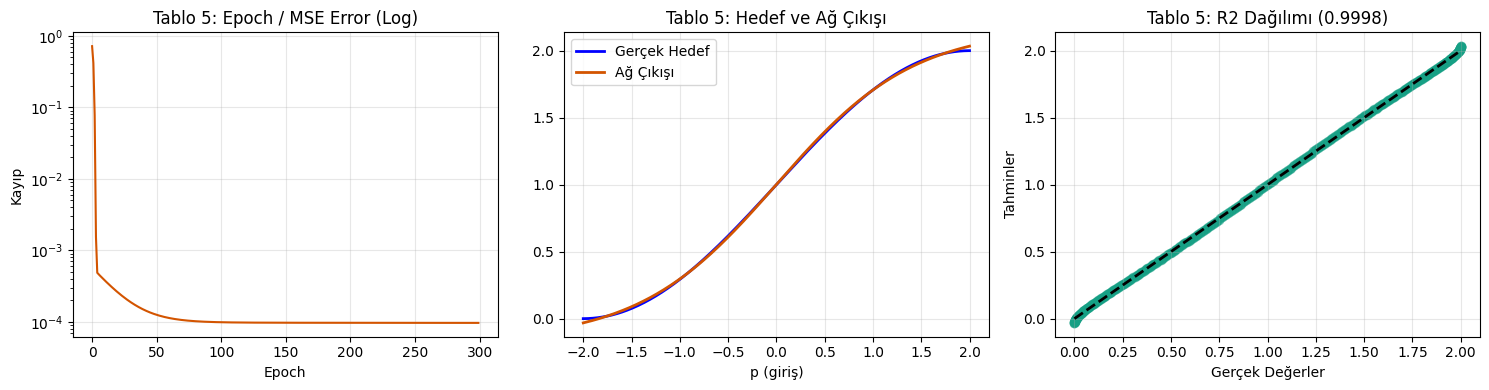

In [11]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

okul_no = 17
np.random.seed(okul_no)
tf.random.set_seed(okul_no)

p_giris = np.linspace(-2, 2, 400).reshape(-1, 1)
t_hedef = 1 + np.sin(np.pi * p_giris / 4)

model = tf.keras.Sequential()
baslangic = tf.keras.initializers.RandomNormal(seed=okul_no)

# En iyi katman sayısı: 1
model.add(tf.keras.layers.Dense(2, activation='tanh', kernel_initializer=baslangic, input_shape=(1,)))
model.add(tf.keras.layers.Dense(1, activation='linear', kernel_initializer=baslangic))

opt = tf.keras.optimizers.SGD(learning_rate=0.1)
model.compile(optimizer=opt, loss='mse')

history = model.fit(p_giris, t_hedef, epochs=300, verbose=0)
tahmin = model.predict(p_giris, verbose=0)
r2 = r2_score(t_hedef, tahmin)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], color='#d35400')
plt.yscale('log')
plt.title('Tablo 5: Epoch / MSE Error (Log)')
plt.xlabel('Epoch')
plt.ylabel('Kayıp')
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(p_giris, t_hedef, label='Gerçek Hedef', color='blue', linewidth=2)
plt.plot(p_giris, tahmin, label='Ağ Çıkışı', color='#d35400', linewidth=2)
plt.title('Tablo 5: Hedef ve Ağ Çıkışı')
plt.xlabel('p (giriş)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)
plt.scatter(t_hedef, tahmin, alpha=0.5, color='#16a085')
plt.plot([t_hedef.min(), t_hedef.max()], [t_hedef.min(), t_hedef.max()], 'k--', lw=2)
plt.title(f'Tablo 5: R2 Dağılımı ({r2:.4f})')
plt.xlabel('Gerçek Değerler')
plt.ylabel('Tahminler')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


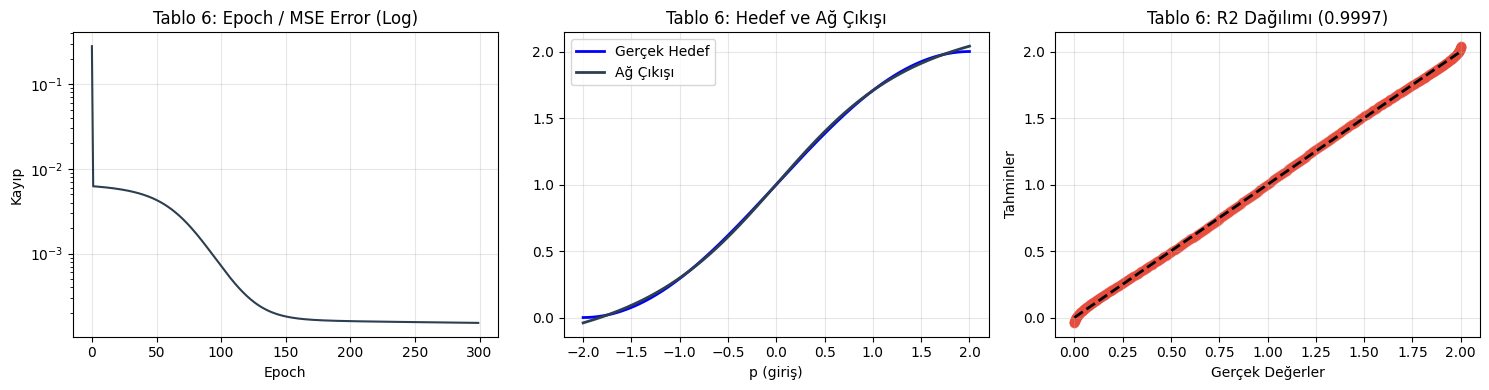

In [12]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

okul_no = 17
np.random.seed(okul_no)
tf.random.set_seed(okul_no)

p_giris = np.linspace(-2, 2, 400).reshape(-1, 1)
t_hedef = 1 + np.sin(np.pi * p_giris / 4)

model = tf.keras.Sequential()
baslangic = tf.keras.initializers.RandomNormal(seed=okul_no)

# En iyi nöron sayısı: 50
model.add(tf.keras.layers.Dense(50, activation='tanh', kernel_initializer=baslangic, input_shape=(1,)))
model.add(tf.keras.layers.Dense(1, activation='linear', kernel_initializer=baslangic))

opt = tf.keras.optimizers.SGD(learning_rate=0.1)
model.compile(optimizer=opt, loss='mse')

history = model.fit(p_giris, t_hedef, epochs=300, verbose=0)
tahmin = model.predict(p_giris, verbose=0)
r2 = r2_score(t_hedef, tahmin)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], color='#2c3e50')
plt.yscale('log')
plt.title('Tablo 6: Epoch / MSE Error (Log)')
plt.xlabel('Epoch')
plt.ylabel('Kayıp')
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(p_giris, t_hedef, label='Gerçek Hedef', color='blue', linewidth=2)
plt.plot(p_giris, tahmin, label='Ağ Çıkışı', color='#2c3e50', linewidth=2)
plt.title('Tablo 6: Hedef ve Ağ Çıkışı')
plt.xlabel('p (giriş)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)
plt.scatter(t_hedef, tahmin, alpha=0.5, color='#e74c3c')
plt.plot([t_hedef.min(), t_hedef.max()], [t_hedef.min(), t_hedef.max()], 'k--', lw=2)
plt.title(f'Tablo 6: R2 Dağılımı ({r2:.4f})')
plt.xlabel('Gerçek Değerler')
plt.ylabel('Tahminler')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import tensorflow as tf
import pandas as pd
import time
from sklearn.metrics import mean_squared_error, r2_score

# Okul no ve veri seti
okul_no = 17
p_giris = np.linspace(-2, 2, 400).reshape(-1, 1)
t_hedef = 1 + np.sin(np.pi * p_giris / 4)

# Tablo 2 için Öğrenme Oranları
ogrenme_oranlari = [0.1, 0.01, 0.001]
sonuclar_t2 = []

print("Tablo 2 (Öğrenme Oranı) hesaplanıyor...\n")

for lr in ogrenme_oranlari:
    np.random.seed(okul_no)
    tf.random.set_seed(okul_no)

    model = tf.keras.Sequential()
    baslangic = tf.keras.initializers.RandomNormal(seed=okul_no)

    # En iyi aktivasyon fonksiyonu olan 'tanh' kullanılıyor
    model.add(tf.keras.layers.Dense(2, activation='tanh', kernel_initializer=baslangic, input_shape=(1,)))
    model.add(tf.keras.layers.Dense(1, activation='linear', kernel_initializer=baslangic))

    opt = tf.keras.optimizers.SGD(learning_rate=lr)
    model.compile(optimizer=opt, loss='mse')

    basla = time.time()
    model.fit(p_giris, t_hedef, epochs=300, verbose=0)
    bitis = time.time()

    sure = bitis - basla
    tahmin = model.predict(p_giris, verbose=0)

    mse = mean_squared_error(t_hedef, tahmin)
    r2 = r2_score(t_hedef, tahmin)

    sonuclar_t2.append([lr, round(mse, 5), round(r2, 5), round(sure, 2)])

df_t2 = pd.DataFrame(sonuclar_t2, columns=["Öğrenme Oranı", "MSE", "R2", "Süre (sn)"])
print(df_t2.to_string(index=False))

Tablo 2 (Öğrenme Oranı) hesaplanıyor...



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


 Öğrenme Oranı     MSE      R2  Süre (sn)
         0.100 0.00010 0.99981      22.96
         0.010 0.00019 0.99962      22.81
         0.001 0.00364 0.99273      20.94
